In [1]:
import pandas as pd


df = pd.read_csv("employees.csv")


df.head()

,Name,Age,Salary,Join_Date,Department
0,Pam,25.0,70200.0,1/15/2023,HR
1,Jane,NaN,65000.0,8/1/2022,Finance
2,Alice,22.0,71350.0,5/20/2021,HR
3,Bob,22.0,NaN,1/15/2023,IT
4,Pam,25.0,71250.0,1/15/2023,HR


In [2]:
df.isnull().sum()

Name          0
Age           4
Salary        7
Join_Date     0
Department    0
dtype: int64

In [3]:

print("Median Age:", df["Age"].median())
print("Median Salary:", df["Salary"].median())

df["Age"] = df["Age"].fillna(df["Age"].median())
df["Salary"] = df["Salary"].fillna(df["Salary"].median())

print("\nMissing Values After Handling:")
print(df.isnull().sum())

Median Age: 36.0
Median Salary: 71841.0

Missing Values After Handling:
Name          0
Age           0
Salary        0
Join_Date     0
Department    0
dtype: int64


In [4]:
print("Number of Duplicate Rows:", df.duplicated().sum())

df[df.duplicated()]

Number of Duplicate Rows: 1


,Name,Age,Salary,Join_Date,Department
31,Sam,40.0,71841.0,9/5/2022,IT


In [5]:
df = df.drop_duplicates()

print("Duplicate Rows After Removal:", df.duplicated().sum())

print("Dataset Shape After Removing Duplicates:", df.shape)

Duplicate Rows After Removal: 0
Dataset Shape After Removing Duplicates: (42, 5)


In [6]:
df["Name"] = df["Name"].str.strip()
df["Department"] = df["Department"].str.strip()

df["Name"] = df["Name"].str.lower()
df["Department"] = df["Department"].str.lower()

df.head()

,Name,Age,Salary,Join_Date,Department
0,pam,25.0,70200.0,1/15/2023,hr
1,jane,36.0,65000.0,8/1/2022,finance
2,alice,22.0,71350.0,5/20/2021,hr
3,bob,22.0,71841.0,1/15/2023,it
4,pam,25.0,71250.0,1/15/2023,hr


In [7]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df["Salary"] < lower_limit) | (df["Salary"] > upper_limit)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("\nSalary Outliers:")
print(outliers[["Name", "Salary", "Department"]])

Q1: 68500.0
Q3: 77421.0
IQR: 8921.0
Lower Limit: 55118.5
Upper Limit: 90802.5

Salary Outliers:
      Name    Salary Department
6   joanne  120000.0         it
15    susy  126001.0         it
18  joanne  125600.0         it
21   norma  921000.0         it
28   jenny  801423.0         it
42     kim  546222.0         hr


In [8]:
df["Join_Date"] = pd.to_datetime(df["Join_Date"], errors="coerce")

print("Join_Date Data Type:", df["Join_Date"].dtype)

df[["Name", "Join_Date"]].head()

Join_Date Data Type: datetime64[us]


,Name,Join_Date
0,pam,2023-01-15
1,jane,2022-08-01
2,alice,2021-05-20
3,bob,2023-01-15
4,pam,2023-01-15


In [9]:
df["Department_Code"] = df["Department"].astype("category").cat.codes

print("Department Encoding:")
print(df[["Department", "Department_Code"]].drop_duplicates())

df.head()

Department Encoding:
  Department  Department_Code
0         hr                1
1    finance                0
3         it                2


,Name,Age,Salary,Join_Date,Department,Department_Code
0,pam,25.0,70200.0,2023-01-15,hr,1
1,jane,36.0,65000.0,2022-08-01,finance,0
2,alice,22.0,71350.0,2021-05-20,hr,1
3,bob,22.0,71841.0,2023-01-15,it,2
4,pam,25.0,71250.0,2023-01-15,hr,1


In [10]:
df.to_csv("employees_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [11]:
cleaned_df = pd.read_csv("employees_cleaned.csv", parse_dates=["Join_Date"])

cleaned_df.head()

,Name,Age,Salary,Join_Date,Department,Department_Code
0,pam,25.0,70200.0,2023-01-15,hr,1
1,jane,36.0,65000.0,2022-08-01,finance,0
2,alice,22.0,71350.0,2021-05-20,hr,1
3,bob,22.0,71841.0,2023-01-15,it,2
4,pam,25.0,71250.0,2023-01-15,hr,1


In [12]:
print("Dataset Shape:", cleaned_df.shape)

print("\nMissing Values:")
print(cleaned_df.isnull().sum())

print("\nDataset Information:")
cleaned_df.info()

Dataset Shape: (42, 6)

Missing Values:
Name               0
Age                0
Salary             0
Join_Date          0
Department         0
Department_Code    0
dtype: int64

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Name             42 non-null     str           
 1   Age              42 non-null     float64       
 2   Salary           42 non-null     float64       
 3   Join_Date        42 non-null     datetime64[us]
 4   Department       42 non-null     str           
 5   Department_Code  42 non-null     int64         
dtypes: datetime64[us](1), float64(2), int64(1), str(2)
memory usage: 2.4 KB


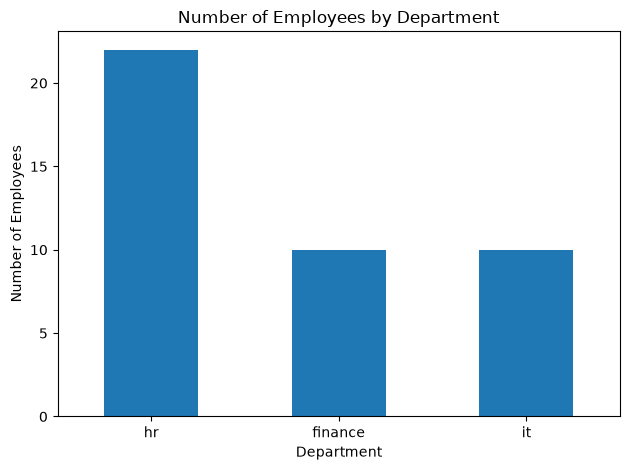

In [13]:
import matplotlib.pyplot as plt

department_counts = cleaned_df["Department"].value_counts()

department_counts.plot(kind="bar")

plt.title("Number of Employees by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

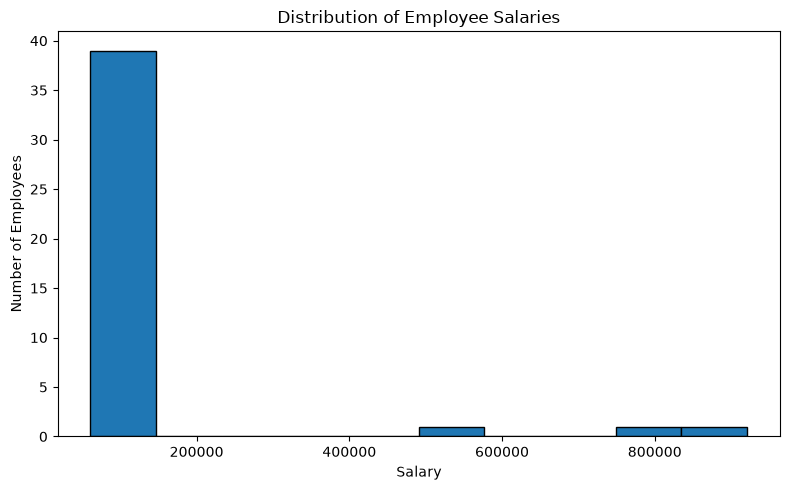

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(cleaned_df["Salary"], bins=10, edgecolor="black")

plt.title("Distribution of Employee Salaries")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

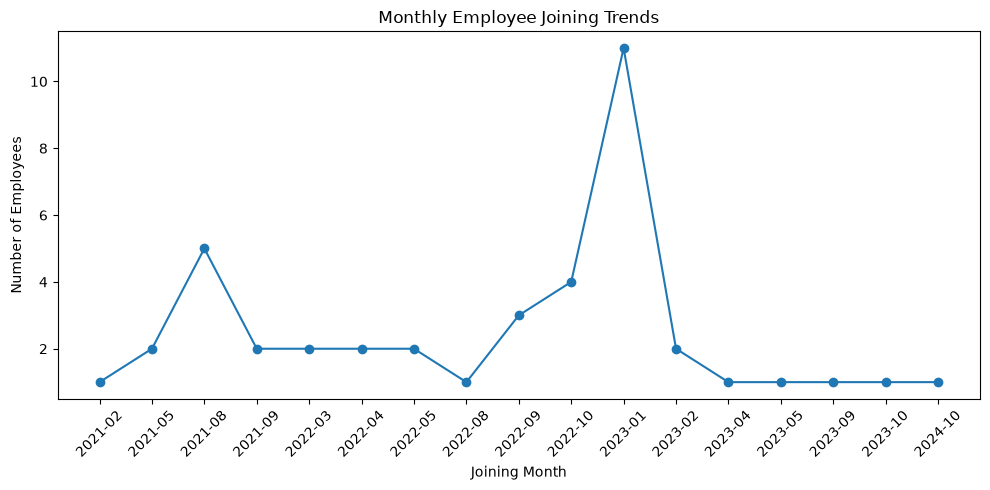

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

cleaned_df["Join_Month"] = cleaned_df["Join_Date"].dt.to_period("M")

monthly_joins = cleaned_df["Join_Month"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(monthly_joins.index.astype(str), monthly_joins.values, marker="o")

plt.title("Monthly Employee Joining Trends")
plt.xlabel("Joining Month")
plt.ylabel("Number of Employees")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

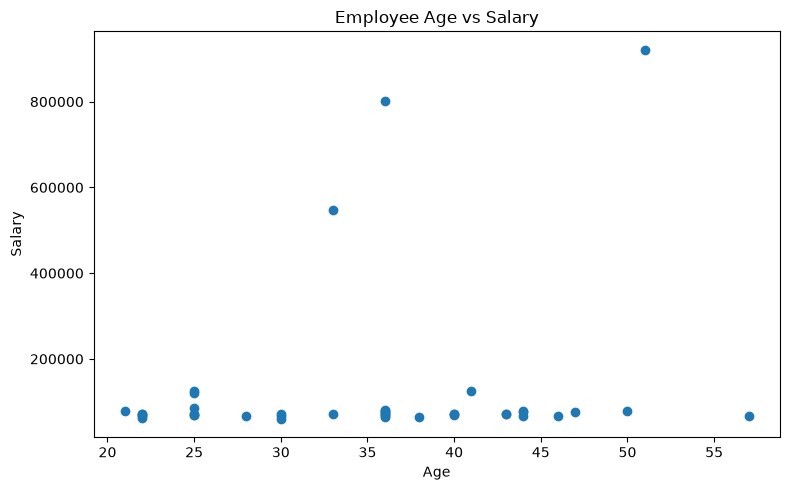

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(cleaned_df["Age"], cleaned_df["Salary"])

plt.title("Employee Age vs Salary")
plt.xlabel("Age")
plt.ylabel("Salary")

plt.tight_layout()
plt.show()

In [17]:
cleaned_df.to_csv("employees_cleaned.csv", index=False)

print("Project completed successfully!")
print("Final dataset saved as employees_cleaned.csv")

Project completed successfully!
Final dataset saved as employees_cleaned.csv
